# CELESTE at a glance

**Conceptual process modelling and exergy analysis in Python**

This notebook is a short tour for colleagues who already model processes with other tools (Aspen Plus/HYSYS,
TESPy, EBSILON, gPROMS, spreadsheets). It answers four questions and shows the tools live:

1. **Why CELESTE?** What it is for in our research, and where it sits next to the tools you know.
2. **What does a normal workflow look like?** From a unit model to a solved, checked flowsheet.
3. **What do you get on top?** Process flow diagram, design specifications, exergy analysis, pinch analysis
   and heat exchanger network synthesis, parameter studies.
4. **How do I make it my own?** Writing a unit model, and what lies beyond (equation-oriented solve, JAX).

Every cell runs in a few seconds. For the step-by-step version (how unit models are built, how to keep your own
component library) see [`Tutorial.ipynb`](Tutorial.ipynb); for the details see the [README](../README.md) and
[`docs/`](../docs).

## 1. Why CELESTE?

### Goals in our research

CELESTE was written for the **early design stage** of energy and chemical conversion processes: power-to-X,
electrolysis (SOEC, AEL), fuel synthesis (methanol, Fischer-Tropsch, methane, ammonia) and heat integration.
At that stage the questions are *"Which concept? Where are the losses? What is the best this process could do?"*
rather than *"What does the column look like?"*. That leads to four goals:

| Goal | What it means in CELESTE |
|---|---|
| **Transparent models** | Every unit is a short Python class with its equations in plain sight. You can read what a reactor solves, print the residuals, and step through it in a debugger. Nothing is a black box. |
| **Second law as a first-class result** | Every unit reports heat `Q`, work `W`, entropy generation `Sgen`, exergy destroyed `Exdest` and exergy lost `Exloss`. Every system closes its mass, energy *and* exergy balance. |
| **From flowsheet to heat integration in one place** | A solved system turns into a pinch-analysis stream table in one line; the network synthesis and the exergy of the integrated plant follow. |
| **A research code you can extend** | It is plain Python (NumPy, SciPy, pandas, JAX): parameter studies, optimisation, plotting and new unit models use the tools you already know, and models are shared through git. |

### Where it sits next to other tools

|  | Aspen Plus / HYSYS | TESPy | CELESTE |
|---|---|---|---|
| Main use | rigorous process simulation, equipment design | thermal power plants, component-based networks | conceptual design, exergy analysis, heat integration |
| Model of a unit | compiled, documented in the manual | equations in a solver class, assembled into one global system | short Python class, equations readable at the call site |
| How a flowsheet is solved | sequential modular (+ EO option) | one global Newton system | sequential modular per unit, recycles torn automatically; EO on top |
| Properties | large databanks, many EOS | CoolProp | NASA polynomials (ideal gas), Peng-Robinson, CoolProp |
| Exergy | stream property; unit balances by post-processing | separate analysis class on a solved network | built into every unit and system |
| Heat integration | Aspen Energy Analyzer | not included | pinch analysis and HEN synthesis on the solved system |
| Scripting, sweeps, derivatives | via automation interfaces | Python | Python; JAX for vectorised sweeps and exact derivatives |

CELESTE is **not** a replacement for a rigorous simulator: it has no column internals, no equipment sizing beyond
heat exchanger areas, and a smaller property library. It is the tool for the hundreds of quick, transparent and
fully balanced concept evaluations that come before.

## 2. A normal workflow

```
  media             units                 system                  solve & check            analyse
 ───────────     ─────────────────     ───────────────────     ──────────────────     ───────────────────────
 which species   reactor, heater,      link(outlet, inlet)     run_sol()              exergy_summary()
 which property  compressor, SOC ...   for every stream        print_equations()      pinch / HEN
 model           design inputs         (order and recycles     MBcheck(), EBcheck()   add_spec(), sweeps
                                        are generated)         pfd()                  your own plots
```

1. **Pick a medium** (the species list and property model), e.g. `media.Fuel_CH4()`.
2. **Create units** with their *design* inputs (efficiency, reactor temperature, ...); the *operating* state
   (flows, temperatures, pressures) lives on the ports, the `Flange`s.
3. **Declare the streams** once with `link(outlet, inlet)`. CELESTE works out the solve order and the tear
   streams of any recycle.
4. **Solve and check**: `run_sol()`, then look at what was solved and whether the balances close.
5. **Analyse**: exergy, heat integration, design specifications and parameter studies.

We walk through these steps now.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from celeste.CSL import SysBase, flow, heat, media, reactors, turbomachinery
from celeste.HEN import HENSynthesiser, PinchAnalyser

warnings.filterwarnings('ignore', category=DeprecationWarning)
pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

### 2.1 One unit in five lines

A methanation reactor at chemical equilibrium (water-gas shift and methane reforming), isothermal at 600 K.
The design input (`T`) goes into the constructor, the feed onto the inlet flange `F0`.

In [2]:
reactor = reactors.MR('methanation', T=600.0)
reactor.F0.n = 10.0                                                  # mol/s
reactor.F0.P = 10.0                                                  # bar
reactor.F0.Xi = np.array([0.60, 0.01, 0.20, 0.10, 0.08, 0.01])       # H2, CH4, CO2, CO, H2O, N2
reactor.run_sol()

print(f'heat duty Q        = {reactor.Q:8.1f} kW  (negative: heat removed)')
print(f'exergy destroyed   = {reactor.Exdest:8.1f} kW')
print(f'exergy lost (heat) = {reactor.Exloss:8.1f} kW')
reactor.F1                                                           # the outlet flange

heat duty Q        =   -347.1 kW  (negative: heat removed)
exergy destroyed   =     65.7 kW
exergy lost (heat) =    174.6 kW


n /mol/s          6.550
m /g/s          146.942
T /K            600.000
P /bar           10.000
h /kJ/mol      -205.694
cp /kJ/mol/K      0.043
Xi_H2             0.015
Xi_CH4            0.279
Xi_CO2            0.194
Xi_CO             0.000
Xi_H2O            0.496
Xi_N2             0.015

**What did it just solve?** No black box: the documentation of the class states the unknowns and the equations,
and the residuals of those equations can be evaluated at any time. After the solve they are at machine precision.

In [3]:
print(reactors.MR.__doc__.split('Isothermal')[0])
print('residuals at the solution:', np.abs(reactor.Eqs()).max())


Methanation / steam reforming reactor with the fuel at water-gas-shift and methane-reforming equilibrium.

System of equations (``Eqs``), the same as in the SOC without current:
    unknowns:  ln of the outlet flows of H2, CH4, CO2, CO, H2O, N2   (+ T_out when Q is specified)
    equations: C, H, O, N balances, WGS and MSR equilibrium         (+ energy balance)
Solving for the logarithms keeps every flow positive, also for trace species. The extents ``xi_WGS``
and ``xi_MSR`` follow from the flows.


residuals at the solution: 1.7763568394002505e-15


### 2.2 A system: declare the streams, CELESTE does the rest

A small substitute natural gas (SNG) plant: compress the H2/CO2 feed, preheat it, methanate it, cool the product.
A system is a class; units are attributes, and every stream is declared once with `link`.

In [4]:
gas = media.Fuel_CH4()                         # H2, CH4, CO2, CO, H2O, N2 with NASA polynomials

class SNGPlant(SysBase):
    def __init__(self, name: str, n: float = 10.0, P: float = 5.0, T_reac: float = 600.0):
        super().__init__(locals())
        self.feed = flow.SourceM('feed', gas, F1_n=n, F1_T=300.0, F1_P=1.0,
                                 F1_Xi=np.array([0.79, 1e-6, 0.20, 1e-6, 1e-6, 0.01]))
        self.comp = turbomachinery.CompIsent('comp', gas, eff=0.8)
        self.comp.F1.P = P                     # operating spec on the flange: discharge pressure
        self.preheat = heat.Heater('preheat', gas)
        self.preheat.F1.T = T_reac
        self.reactor = reactors.MR('reactor', gas, T=T_reac)
        self.cooler = heat.Heater('cooler', gas)
        self.cooler.F1.T = 313.15
        self.product = flow.Sink('product', gas)

        self.link(self.feed.F1, self.comp.F0)
        self.link(self.comp.F1, self.preheat.F0)
        self.link(self.preheat.F1, self.reactor.F0)
        self.link(self.reactor.F1, self.cooler.F0)
        self.link(self.cooler.F1, self.product.F0)

plant = SNGPlant('sng')
plant.print_solve_order();

1. feed((feed))
2. comp
3. preheat
4. reactor
5. cooler
6. product[(product)]


Solve it, then ask **what each unit solved**. This is the readable per-unit solve: the reactor solves its six
equations, the other units assign their outlet directly from their inlet. Each line comes from the unit's own
`Eqs` docstring, so the printout stays in step with the code.

In [5]:
plant.run_sol()
plant.print_equations();

sng: 6 units, 1 solve a system of equations (6 equations), the rest are algorithmic
  comp (CompIsent): outlet assigned from the inlet
  cooler (Heater): outlet assigned from the inlet
  feed (SourceM): outlet assigned from the inlet
  preheat (Heater): outlet assigned from the inlet
  product (Sink): outlet assigned from the inlet
  reactor (MR): 6 equations in 6 unknowns, max |residual| 3.55e-15
      Isothermal: element balances, WGS and MSR equilibrium.
streams declared with link(): 5 (copied between the units in the solve order)


Every result is an ordinary pandas object, and every balance is checked:

In [6]:
print(f'mass balance error   {plant.MBcheck():.1e} g/s')
print(f'energy balance error {plant.EBcheck():.1e} kW')
print(f'CH4 in the product   {plant.product.F0.Xi[1]:.3f} (wet)')
pd.concat([plant.work_df().rename('W / kW'), plant.heater_df()['Q'].rename('Q / kW')], axis=1)

mass balance error   7.1e-14 g/s
energy balance error 0.0e+00 kW
CH4 in the product   0.308 (wet)


,W / kW,Q / kW
sng.comp,62.705,NaN
sng.cooler,NaN,-66.565
sng.preheat,NaN,33.041


### 2.3 The process flow diagram

`pfd()` draws the flowsheet from the declared streams. **Hover** over a stream for its state and composition, over a
unit for its duties and exergy; click to pin. In a notebook it displays itself; `pfd('plant.html')` saves a page you
can send around.

In [7]:
plant.pfd()

### 2.4 Design specifications: asking the inverse question

*"Which reactor temperature gives 30 % methane in the product?"* A design specification adjusts an input until a
target is met; every iteration is a full solve of the system (recycles included). Targets and inputs are paths
in the system, or any function of it.

In [8]:
plant.add_spec(lambda s: s.product.F0.Xi[1], 0.30, vary='reactor.T', bounds=(500.0, 900.0))
plant.solve_specs()
plant.specs

,spec,value,current,vary,input,lower,upper
0,<lambda>,0.300,0.300,reactor.T,629.019,500.000,900.000


## 3. The tools on top: a methanol synthesis loop

A ready-made system from the standard library: make-up gas is mixed with the recycle, preheated, converted in an
isothermal reactor, the methanol is condensed and separated, and a small purge leaves the loop.

In [9]:
from celeste.CSL.systems.ProcessBoxes import MethanolLoop

loop = MethanolLoop('loop', n_feed=100.0, T_reac=523.15, P=50.0, T_cond=313.15, purge=0.02)
loop.print_solve_order();

1. loop.feed((loop.feed))
2. loop [loop.mix, loop.preheat, loop.reactor, loop.cond, loop.split]  tear: loop.split.F1 -> loop.mix.F1
3. loop.product[(loop.product)]
4. loop.purge_out[(loop.purge_out)]


The loop was found from the links, and `split.F1 -> mix.F1` was chosen as the **tear stream**: its value is
guessed, the loop is run, and the guess is updated (accelerated fixed point) until it no longer changes.

In [10]:
passes, error = loop.run_sol()
print(f'recycle converged in {passes} passes (relative error {error:.0e})')
print(f'recycle ratio      {loop.recycle_ratio:.2f}')
print(f'carbon efficiency  {loop.carbon_efficiency:.3f}')
print(f'crude methanol     {loop.product.F0.n:.1f} mol/s at x_MeOH = {loop.product.F0.Xi[6]:.3f}')

recycle converged in 21 passes (relative error 2e-10)
recycle ratio      5.16
carbon efficiency  0.909
crude methanol     42.1 mol/s at x_MeOH = 0.561


### 3.1 PFD view

The recycle is dashed, and the condenser (`cond`) is itself a system (a cooler and a flash drum) drawn as one box.

In [11]:
loop.pfd()

<small>Static snapshot of the same diagram, with the recycle stream hovered (for viewers such as GitHub that do not
run the interactive diagram):</small>

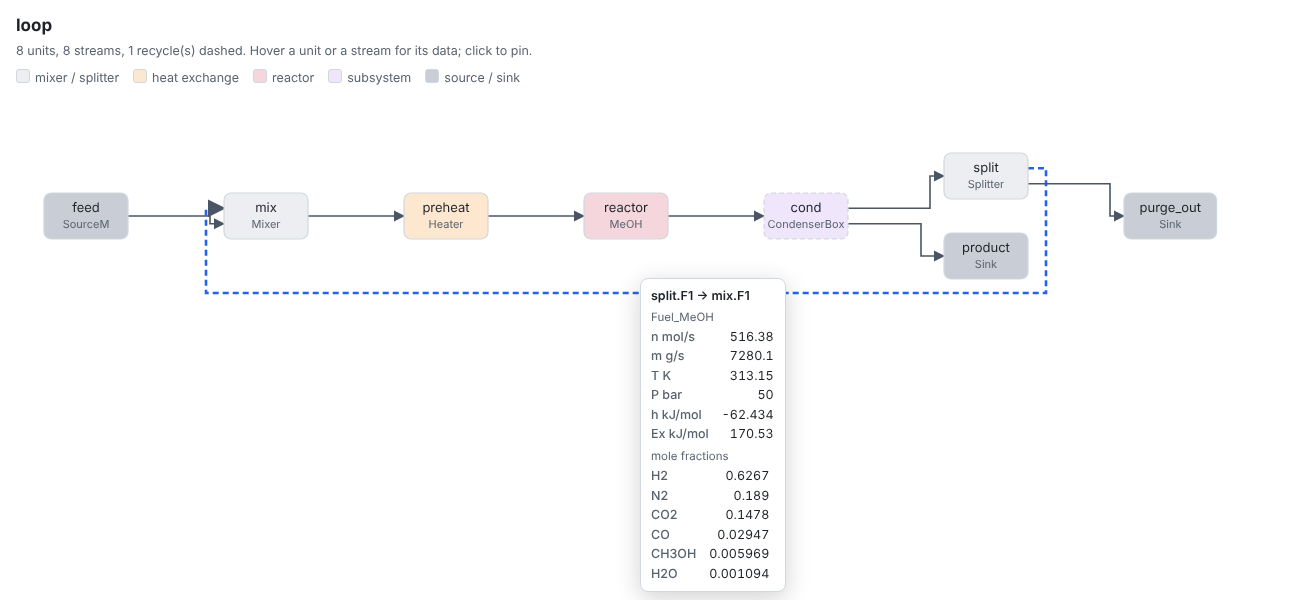

In [12]:
Image('../docs/figures/pfd_methanol_loop.png', width=900)

### 3.2 Exergy analysis

Every unit splits its second-law loss into exergy **destroyed** inside the unit (`Exdest = T0·Sgen`) and exergy
**lost** to the environment with rejected heat (`Exloss`). The system sets up the exergy balance

```
Ex_in = Ex_product + Ex_unused + Exloss + Exdest + Ex_balance
```

where `Ex_balance` is a data-consistency check: it is zero when the property models of all streams agree, and
anything else shows up there instead of being hidden. The system also reports the exergy efficiency, together with the best efficiency this concept could reach if every
irreversibility were removed (`efficiency_max`). Here only the crude methanol counts as product; the purge is
exergy left unused.

In [13]:
ex = loop.exergy_summary(products='product')
ex[['Ex_in', 'Ex_product', 'Ex_unused', 'Exloss', 'Exdest', 'Ex_balance', 'efficiency', 'efficiency_max']].to_frame('kW, or -')

,"kW, or -"
Ex_in,"23,862.076"
Ex_product,"17,174.478"
Ex_unused,"1,797.126"
Exloss,959.381
Exdest,"3,930.519"
Ex_balance,0.571
efficiency,0.720
efficiency_max,0.884


/home/user/CELESTE/celeste/CSL/_mixin/analysis.py:188: UserWarning: exergy_df: negative exergy destruction (T0*Sgen < 0) in ['loop.cond.drum']: the second law is violated inside the unit, the property models of its streams are not consistent (for example a flash with NASA media: phase split from the Peng-Robinson equation)
  warnings.warn(f'exergy_df: negative exergy destruction (T0*Sgen < 0) in {list(neg)}: the second law is violated '


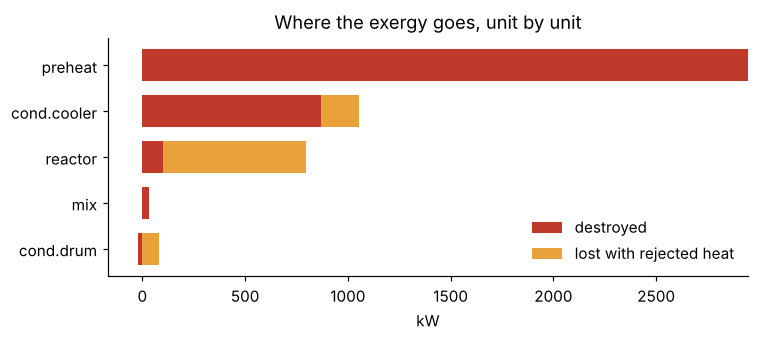

In [14]:
by_unit = loop.exergy_df()
by_unit.index = [i.removeprefix('loop.') for i in by_unit.index]
by_unit = by_unit[(by_unit.abs() > 1e-6).any(axis=1)].sort_values('Exdest')

fig, ax = plt.subplots(figsize=(7, 3.2))
by_unit[['Exdest', 'Exloss']].plot.barh(stacked=True, ax=ax, color=['#c0392b', '#e9a23b'], width=0.7)
ax.set_xlabel('kW'); ax.set_title('Where the exergy goes, unit by unit')
ax.legend(['destroyed', 'lost with rejected heat'], frameon=False)
plt.tight_layout(); plt.show()

The **preheater** dominates: it heats the loop gas from 40 °C to 250 °C with an external utility, while the
**condenser** throws a similar amount of heat away. That is the classic signature of a missing heat recovery, which
is exactly what the next tool addresses.

<small>The warning above is CELESTE checking itself: the flash drum shows a slightly negative destruction
(`T0·Sgen` of about -20 kW, 0.5 % of the total), and property mismatches like this one are what keep `Ex_balance`
from being exactly zero (0.6 kW of 23,900 kW in). The drum takes its
phase split from the Peng-Robinson equation but its stream properties from the NASA ideal-gas medium. A
Peng-Robinson medium is consistent; see `docs/known_issues.md`.</small>

### 3.3 Pinch analysis and heat exchanger network (HEN)

One line turns the heaters and coolers of the solved system into a pinch stream table. The same table feeds
the pinch analysis (energy targets) and the network synthesis (a stage-wise superstructure solved as a MILP, giving
the matches, areas and annual cost).

In [15]:
streams = loop.pinch_stream_table()
streams

,segment_type,side,T_in,T_out,CP,T_phase,Q
segment_id,,,,,,,
cond.cooler,sensible,hot,250.000,40.000,18.352,NaN,NaN
preheat,sensible,cold,40.000,250.000,19.301,NaN,NaN


In [16]:
pinch = PinchAnalyser(streams, dt_min=10).solve()
pinch.summary()[['hot_utility', 'cold_utility', 'heat_recovery', 'pinch_hot', 'pinch_cold']].to_frame('target (kW, °C)')

,"target (kW, °C)"
hot_utility,382.757
cold_utility,183.519
heat_recovery,"3,670.374"
pinch_hot,[50.0]
pinch_cold,[40.0]


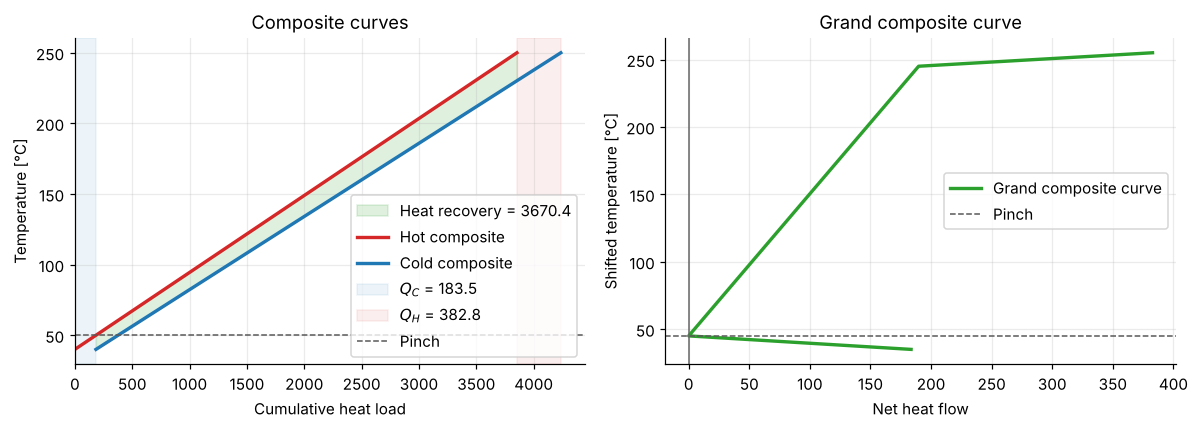

In [17]:
fig, _ = pinch.plot_summary(figsize=(11, 4))
plt.show()

In [18]:
hen = HENSynthesiser(streams, dt_min=10).solve()
hen.summary()[['hot_utility', 'hot_utility_target', 'cold_utility', 'cold_utility_target',
               'heat_recovery', 'n_exchangers', 'total_area', 'total_annual_cost']].to_frame('network')

,network
hot_utility,474.564
hot_utility_target,382.757
cold_utility,275.325
cold_utility_target,183.519
heat_recovery,"3,578.568"
n_exchangers,1
total_area,443.238
total_annual_cost,"150,093.641"


For the loop alone the answer is one feed-effluent exchanger: the hot reactor product preheats the loop gas, and
only small trim heater and cooler duties remain.

The stream table is an ordinary DataFrame, so the same tools work **across plants**. Here the methanol loop and a
larger SNG plant from section 2 share one site, and the synthesis finds the matches between them:

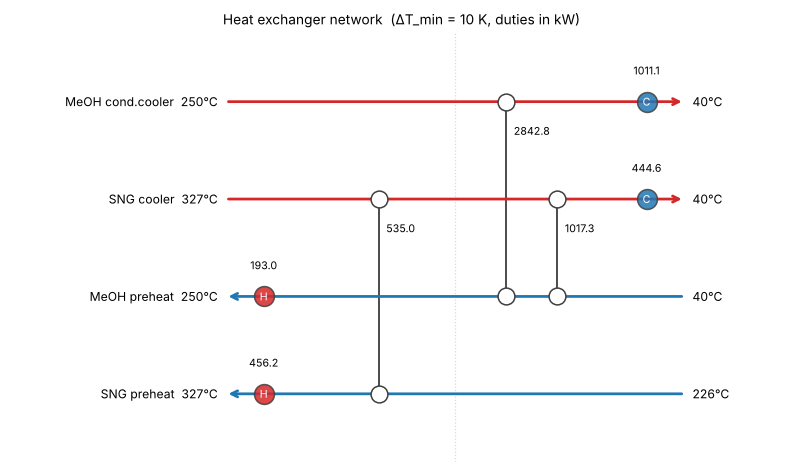

,hot,cold,Q,area,cost
0,SNG cooler,SNG preheat,535.001,31.184,"15,836.351"
1,MeOH cond.cooler,MeOH preheat,"2,842.782",217.217,"45,024.100"
2,SNG cooler,MeOH preheat,"1,017.343",70.949,"23,126.038"


In [19]:
sng = SNGPlant('sng', n=300.0)
sng.run_sol()
site = pd.concat([loop.pinch_stream_table().rename(index=lambda i: 'MeOH ' + i),
                  sng.pinch_stream_table().rename(index=lambda i: 'SNG ' + i)])
site_hen = HENSynthesiser(site, dt_min=10).solve()
fig, _ = site_hen.plot_grid_diagram()
plt.show()
site_hen.network[['hot', 'cold', 'Q', 'area', 'cost']]

### 3.4 Exergy of the heat-integrated plant

Feeding the network back into the exergy balance answers the question that matters for the concept: *how much
better is the integrated plant?* The recovered heat no longer has to be supplied to the preheater or rejected in
the cooler; the new exchanger destroys a little exergy through its temperature difference.

In [20]:
ex_int = loop.exergy_summary(products='product', hen=hen)
pd.DataFrame({'stand-alone': ex, 'heat-integrated': ex_int}).loc[
    ['Ex_in', 'Ex_product', 'Exloss', 'Exdest', 'efficiency']]

,stand-alone,heat-integrated
Ex_in,"23,862.076","20,283.508"
Ex_product,"17,174.478","17,174.478"
Exloss,959.381,787.967
Exdest,"3,930.519",523.366
efficiency,0.720,0.847


In [21]:
loop.hen_exergy(hen)

,hot,cold,Q,T_lm_hot,T_lm_cold,Ex_hot,Ex_cold,Exdest
0,cond.cooler,preheat,"3,578.568",418.100,398.696,"1,026.666",902.471,124.195


### 3.5 A parameter study in a loop

Because a system is just a Python object, a study is a `for` loop. The purge fraction trades carbon efficiency
(less purge, more recycle) against the size of the recycle. Each point below is a converged recycle, an exergy
balance, a pinch analysis and a network synthesis.

In [22]:
rows = []
for purge in [0.01, 0.015, 0.02, 0.03, 0.05, 0.08, 0.12]:
    case = MethanolLoop('loop', purge=purge)
    case.run_sol()
    net = HENSynthesiser(case.pinch_stream_table(), dt_min=10).solve()
    rows.append(dict(purge=purge,
                     carbon_efficiency=case.carbon_efficiency,
                     recycle_ratio=case.recycle_ratio,
                     exergy_eff=case.exergy_summary(products='product').efficiency,
                     exergy_eff_integrated=case.exergy_summary(products='product', hen=net).efficiency))
study = pd.DataFrame(rows).set_index('purge')
study

,carbon_efficiency,recycle_ratio,exergy_eff,exergy_eff_integrated
purge,,,,
0.010,0.944,7.057,0.712,0.875
0.015,0.926,5.833,0.720,0.861
0.020,0.909,5.164,0.720,0.847
0.030,0.877,4.408,0.709,0.819
0.050,0.821,3.638,0.678,0.769
0.080,0.751,3.006,0.631,0.704
0.120,0.674,2.471,0.576,0.634


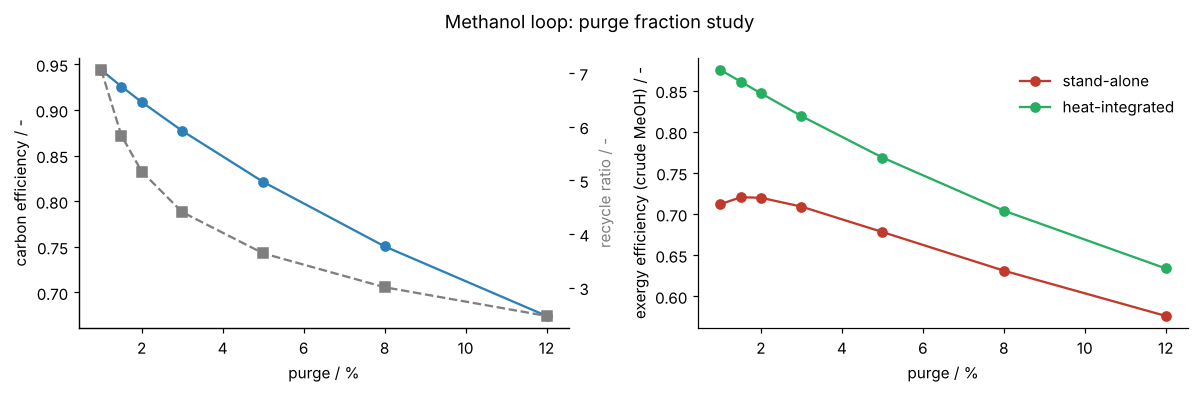

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(study.index*100, study.carbon_efficiency, 'o-', color='#2c7fb8')
a1.set_xlabel('purge / %'); a1.set_ylabel('carbon efficiency / -')
a1r = a1.twinx(); a1r.plot(study.index*100, study.recycle_ratio, 's--', color='#7f7f7f')
a1r.set_ylabel('recycle ratio / -', color='#7f7f7f'); a1r.spines['top'].set_visible(False)
a2.plot(study.index*100, study.exergy_eff, 'o-', color='#c0392b', label='stand-alone')
a2.plot(study.index*100, study.exergy_eff_integrated, 'o-', color='#27ae60', label='heat-integrated')
a2.set_xlabel('purge / %'); a2.set_ylabel('exergy efficiency (crude MeOH) / -'); a2.legend(frameon=False)
fig.suptitle('Methanol loop: purge fraction study'); plt.tight_layout(); plt.show()

The two efficiencies tell different stories. Stand-alone, the exergy efficiency has a flat optimum near 1.5-2 %
purge: less purge puts more carbon into the product, but the growing recycle has to be reheated and cooled again.
With heat integration that penalty is recovered and the exergy efficiency follows the carbon efficiency (recycle
compression is not part of this simple loop). Questions like this, answered in a few lines and seconds, are the
everyday use of CELESTE.

## 4. Making it your own

### 4.1 A new unit model in a dozen lines

A heater with a **given duty** that finds its outlet temperature. It reuses the standard `Heater` (ports, `Q`,
exergy) and adds only the one equation; the docstring of `Eqs` is what `print_equations()` will show.

In [24]:
from celeste import solvers

class DutyHeater(heat.Heater):
    '''Heater with a given duty Q_spec [kW]; the outlet temperature follows.'''

    def __init__(self, name: str, Medium, Q_spec: float = 0.0):
        super().__init__(name, Medium)
        self.Q_spec, self.n_unknowns = Q_spec, 1

    def Eqs(self):
        '''Energy balance: n*(h_F1 - h_F0) - Q_spec = 0 (unknown: T_F1).'''
        super().Eqs()                                   # outlet takes the inlet flow, composition, pressure
        return np.array([(self.Q - self.Q_spec)/self.F0.n])

    def f_sol(self, x):
        self.F1.T = x[0]
        return self.Eqs()

    def run_sol(self):
        return solvers.solve(self.f_sol, np.array([self.F0.T]), name=self.name)

It drops into a system like any library unit:

In [25]:
class AirHeating(SysBase):
    def __init__(self, name: str, Q: float = 25.0):
        super().__init__(locals())
        self.air = flow.SourceM('air', media.Air(), F1_n=1.0, F1_T=300.0, F1_P=1.0)
        self.heater = DutyHeater('heater', media.Air(), Q_spec=Q)
        self.out = flow.Sink('out', media.Air())
        self.link(self.air.F1, self.heater.F0)
        self.link(self.heater.F1, self.out.F0)

demo = AirHeating('demo', Q=25.0)
demo.run_sol()
demo.print_equations()
print(f'\noutlet temperature {demo.out.F0.T:.1f} K, Q = {demo.heater.Q:.2f} kW, Exdest = {demo.heater.Exdest:.2f} kW')

demo: 3 units, 1 solve a system of equations (1 equations), the rest are algorithmic
  air (SourceM): outlet assigned from the inlet
  heater (DutyHeater): 1 equations in 1 unknowns, max |residual| 2.49e-14
      Energy balance: n*(h_F1 - h_F0) - Q_spec = 0 (unknown: T_F1).
  out (Sink): outlet assigned from the inlet
streams declared with link(): 2 (copied between the units in the solve order)

outlet temperature 1099.6 K, Q = 25.00 kW, Exdest = 11.91 kW


To keep models like this in your own library (and share them through git), see Part 2 of
[`Tutorial.ipynb`](Tutorial.ipynb) and [`docs/conventions.md`](../docs/conventions.md).

### 4.2 Beyond sequential solving

* **Equation-oriented solve.** The same declared streams can be solved all at once: every stream becomes an unknown
  and every unit contributes its equations (`system.eo_sol()`, `solve_specs(eo=True)`). The sequential solve stays
  the default and the starting point.
* **JAX.** The property kernel runs on JAX as well, so batches of states and exact derivatives are one line, and
  JAX flowsheets (`celeste.jx.Flowsheet`) can be compiled, vectorised over operating points and differentiated
  (see `examples/04_jax.py` and `examples/05_soec_flowsheet.py`).

In [26]:
seq = SNGPlant('seq')
seq.run_sol()                                   # sequential modular, unit by unit
eo = SNGPlant('eo')
res = eo.eo_sol()                               # all equations at once
print(f'equation-oriented: {res.x.size} unknowns, residual norm {res.residual_norm:.1e}')
print(f'CH4 in the product: sequential {seq.product.F0.Xi[1]:.6f}, equation-oriented {eo.product.F0.Xi[1]:.6f}')

equation-oriented: 51 unknowns, residual norm 8.9e-16
CH4 in the product: sequential 0.307503, equation-oriented 0.307503


In [27]:
import jax, jax.numpy as jnp
from celeste.jx import ideal

air = ideal.ideal_gas(['O2', 'N2'])
x = jnp.array([0.21, 0.79])
T = jnp.linspace(300.0, 1500.0, 100_000)
h = jax.vmap(ideal.enthalpy, (0, None, None))(T, x, air)       # 100 000 states in one call
cp = jax.grad(ideal.enthalpy)(800.0, x, air)                   # exact derivative dh/dT
print(f'h(1500 K) = {float(h[-1]):.3f} kJ/mol,  cp(800 K) = dh/dT = {float(cp)*1000:.2f} J/mol/K')

h(1500 K) = 38.868 kJ/mol,  cp(800 K) = dh/dT = 31.92 J/mol/K


## 5. Questions colleagues usually ask

**Can I trust the numbers?**
Every unit model has tests for its mass, element and energy balance and for the second law
(`Exdest = T0·Sgen`); the property kernels are tested against reference values, the equation of state and flash
against reference fluids and an independent implementation (300+ tests run on every pull request). Changes that
alter results are listed in the changelog. And because every system checks its own balances, you see it
immediately when a model of yours does not close.

**Which property models are there?**
Ideal-gas NASA polynomials (fast, the default for gas-phase process chains), Peng-Robinson for real fluids and
vapour-liquid equilibria, CoolProp media, and a Fischer-Tropsch library (C1-C50 with a liquid phase). A medium is a
short class, so a new species list is a few lines.

**How fast is it?**
A unit solves in about a millisecond, the methanol loop with its recycle in about a second (this whole notebook runs in under a minute), so studies of
hundreds of cases run in minutes on a laptop. JAX takes over where millions of evaluations or derivatives are needed.

**What about the Aspen models we already have?**
CELESTE does not import Aspen files. The usual way is to rebuild the concept-level flowsheet (typically a few dozen
lines), compare it against the Aspen results at one point, and then use CELESTE for the studies, the exergy and the
heat integration.

**How is it different from TESPy?**
Both are open Python tools. TESPy assembles one global equation system for thermal power plants; CELESTE solves unit
by unit with readable equations per unit (and can solve equation-oriented on top), puts exergy into every unit,
covers chemical conversion (equilibrium and kinetic reactors, electrolysers, separation) and brings heat
integration with it.

**What are its limits?**
Conceptual level: no rigorous columns or equipment design, steady state only, and the flash with NASA media is
an approximation (see [`docs/known_issues.md`](../docs/known_issues.md) and
[`docs/sharp_corners.md`](../docs/sharp_corners.md)).

**How do I start?**
`pip install git+https://github.com/DLR-TT-ESI-EHT/CELESTE.git`, then [`Tutorial.ipynb`](Tutorial.ipynb) and the
scripts in [`examples/`](../examples). New unit models, media and validation cases are welcome as pull requests.